# 05 · Final test evaluation, SHAP & error analysis

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))
import pandas as pd, numpy as np
from IPython.display import Image, display, Markdown
from src import config
pd.set_option('display.width', 160); pd.set_option('display.max_columns', 40)
M, F = config.METRICS_DIR, config.FIG_DIR
show = lambda name, w=900: display(Image(filename=str(F / name), width=w))

In [2]:
final = json.loads((M/'final_results.json').read_text())
for t in ('total','per_ha'):
    display(Markdown(f'### Target `{t}` — best by CV: **{final[t]["best_model_by_cv"]}**'))
    display(pd.read_csv(M/f'test_results_{t}.csv').round(4))

### Target `total` — best by CV: **LightGBM (Optuna)**

,model,cv_R2,cv_RMSE,test_R2,test_RMSE,test_MAE,test_MAPE_%
0,Mean predictor (reference),-0.0006,9257.1517,-0.0000,9286.7577,8047.2993,58.3396
1,Hectares-only OLS (reference),0.9888,977.9200,0.9882,1010.3378,752.1362,3.7662
2,Linear Regression,0.9888,976.9084,0.9882,1006.9741,754.1793,3.8306
3,Random Forest,0.9909,880.5404,0.9893,962.2469,690.0525,3.0887
4,Extra Trees,0.9904,904.8526,0.9888,983.6317,701.3769,3.1439
5,Gradient Boosting,0.9917,839.9168,0.9908,891.8636,633.4166,2.8295
6,LightGBM,0.9911,873.8117,0.9894,955.7983,682.7554,3.0453
7,XGBoost,0.9906,896.4548,0.9888,980.9716,695.2688,3.1101
8,LightGBM (Optuna),0.9919,830.4915,0.9910,880.6401,623.8696,2.7736
9,XGBoost (Optuna),0.9918,836.7690,0.9911,874.5507,623.3233,2.7679


### Target `per_ha` — best by CV: **LightGBM (Optuna)**

,model,cv_R2,cv_RMSE,test_R2,test_RMSE,test_MAE,test_MAPE_%
0,Mean predictor (reference),-0.0007,287.6900,-0.0020,295.7075,255.7242,4.3206
1,Hectares-only OLS (reference),0.3514,231.4208,0.3510,237.9948,187.0415,3.1737
2,Linear Regression,0.3482,231.9997,0.3523,237.7559,186.6003,3.1660
3,Random Forest,0.4438,214.0767,0.3790,232.8005,181.8607,3.0876
4,Extra Trees,0.4131,219.9745,0.3464,238.8362,185.1271,3.1429
5,Gradient Boosting,0.5007,202.8739,0.4830,212.4204,165.2497,2.8083
6,LightGBM,0.4501,212.8858,0.3938,230.0064,180.5392,3.0660
7,XGBoost,0.4182,219.0124,0.3607,236.2036,183.4608,3.1157
8,LightGBM (Optuna),0.5133,200.2297,0.4955,209.8215,162.9402,2.7691
9,XGBoost (Optuna),0.5074,201.4396,0.4939,210.1693,164.2588,2.7913


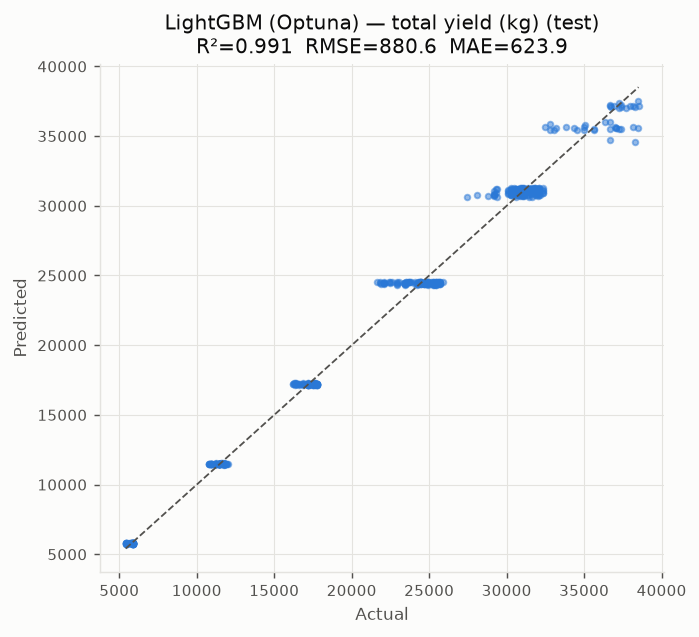

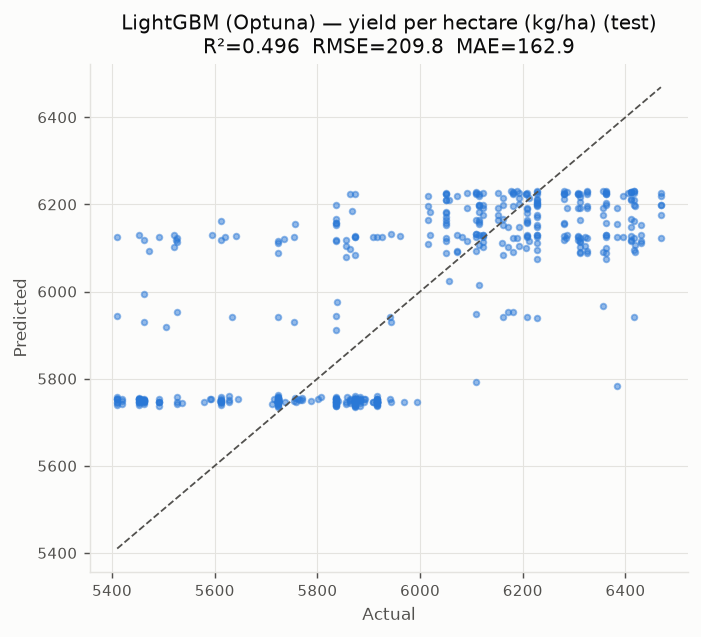

In [3]:
show('pred_vs_actual_total.png', 450); show('pred_vs_actual_per_ha.png', 450)

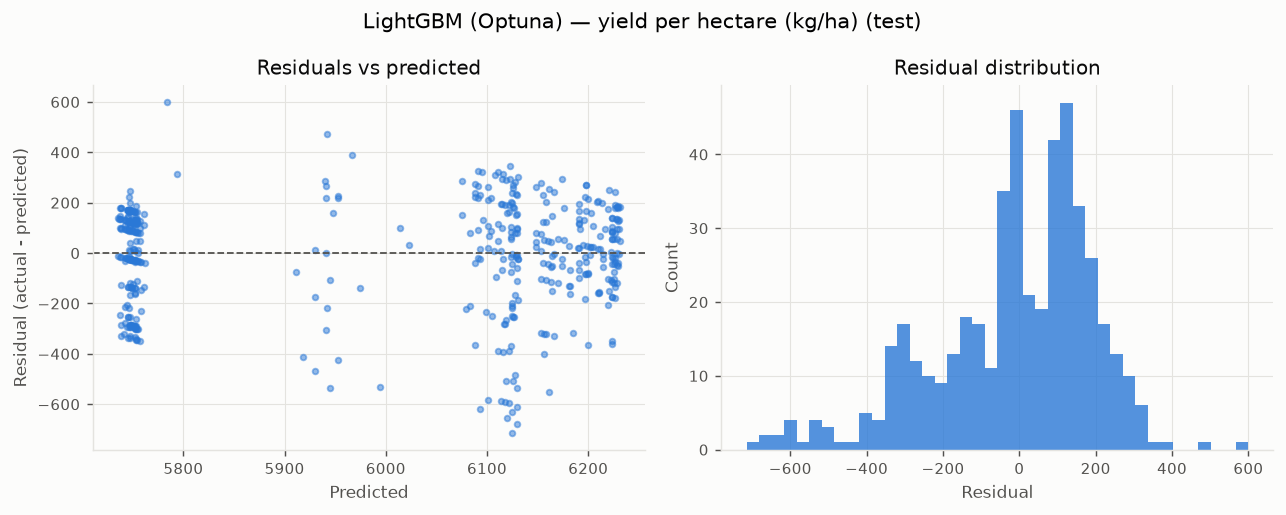

In [4]:
show('residuals_per_ha.png')

## SHAP — yield per hectare

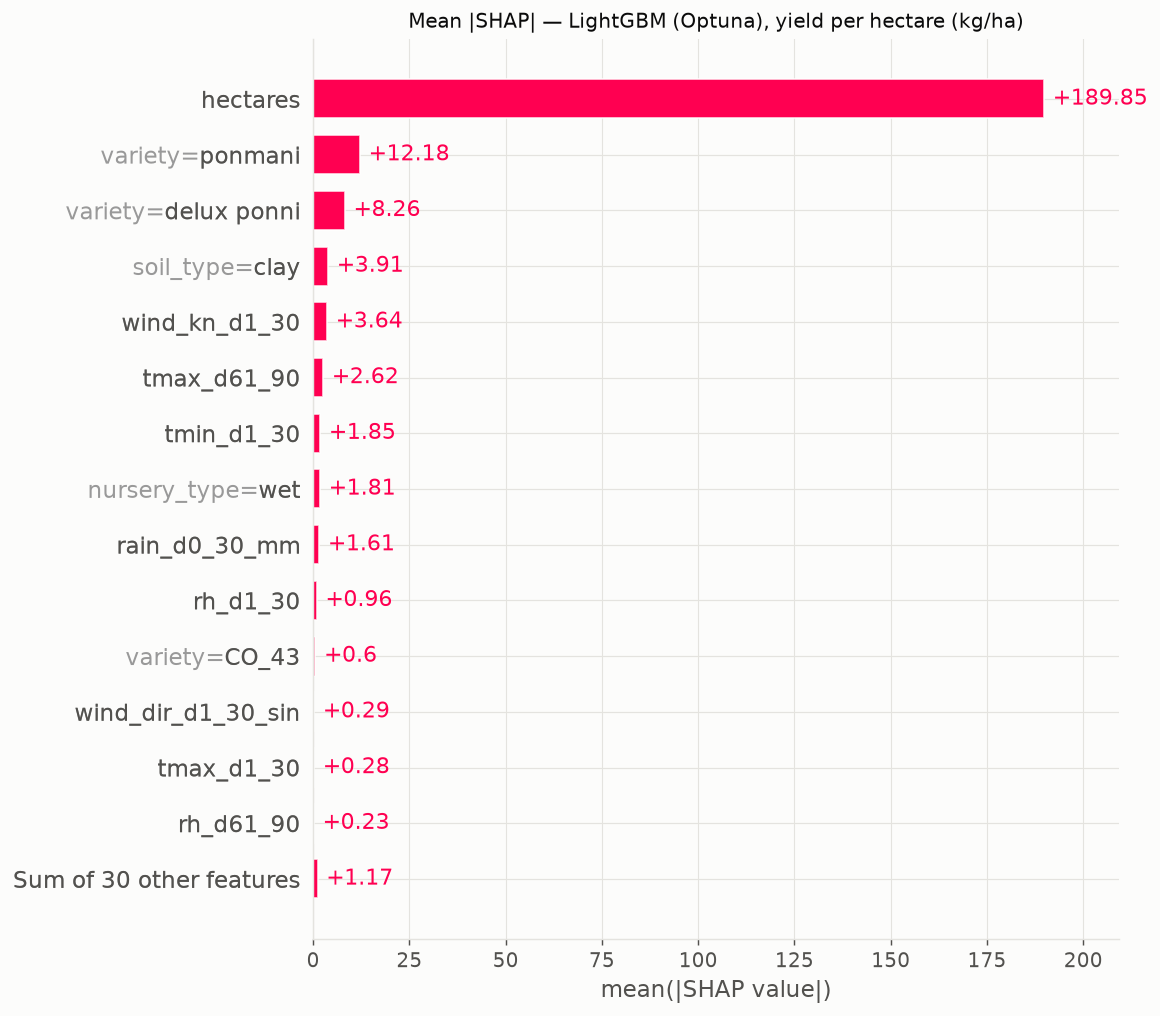

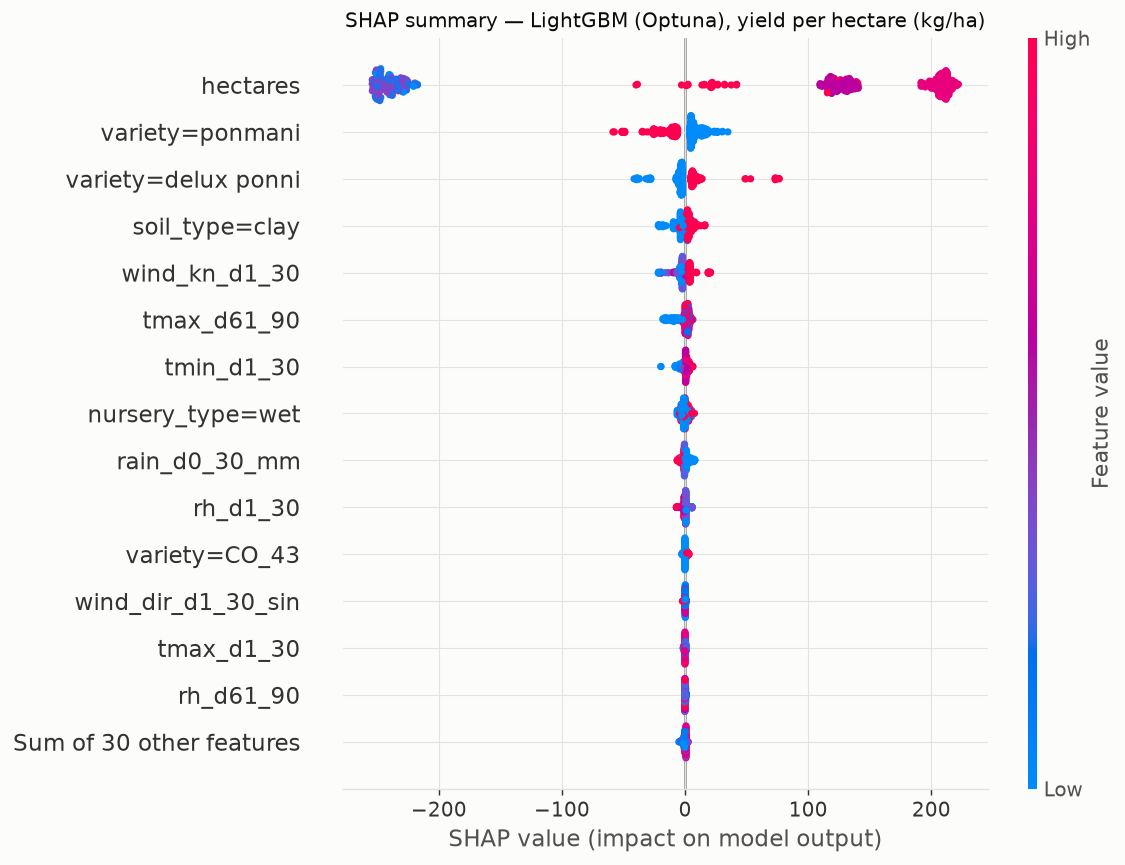

In [5]:
show('shap_per_ha_bar.png', 650); show('shap_per_ha_summary.png', 650)

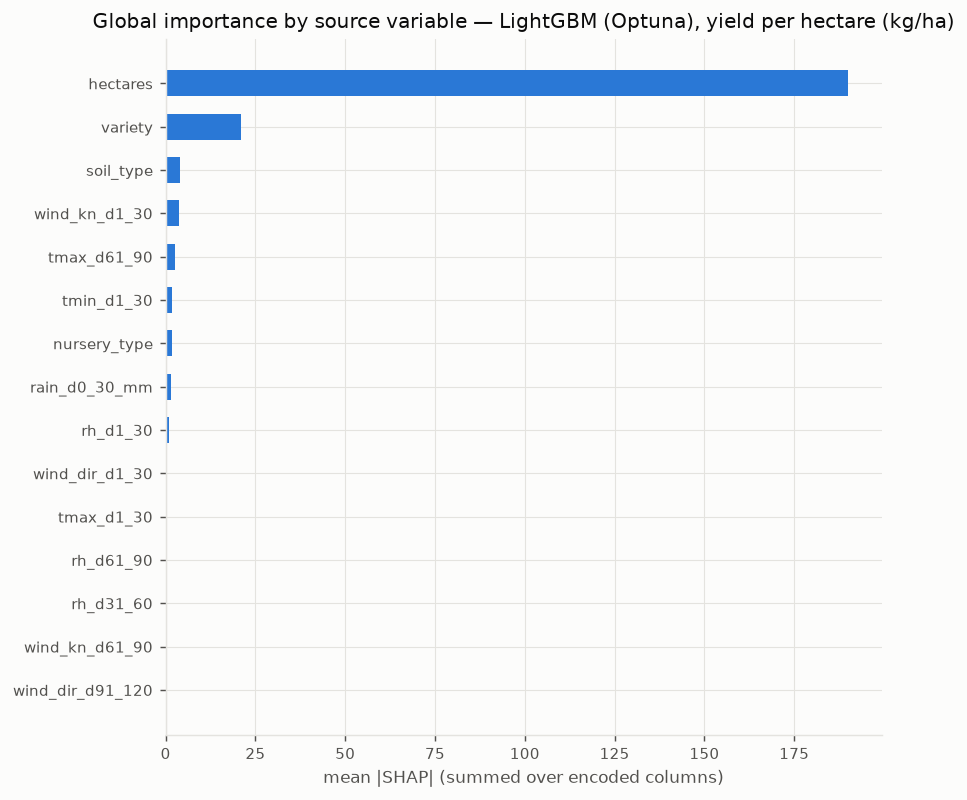

In [6]:
show('shap_per_ha_grouped_importance.png', 650)

In [7]:
pd.read_csv(M/'shap_importance_grouped_per_ha.csv', index_col=0).head(12)

,mean_abs_shap,share_%
hectares,189.847,82.807
variety,21.047,9.180
soil_type,3.909,1.705
wind_kn_d1_30,3.637,1.586
tmax_d61_90,2.619,1.142
tmin_d1_30,1.854,0.809
nursery_type,1.814,0.791
rain_d0_30_mm,1.608,0.701
rh_d1_30,0.961,0.419
wind_dir_d1_30,0.316,0.138


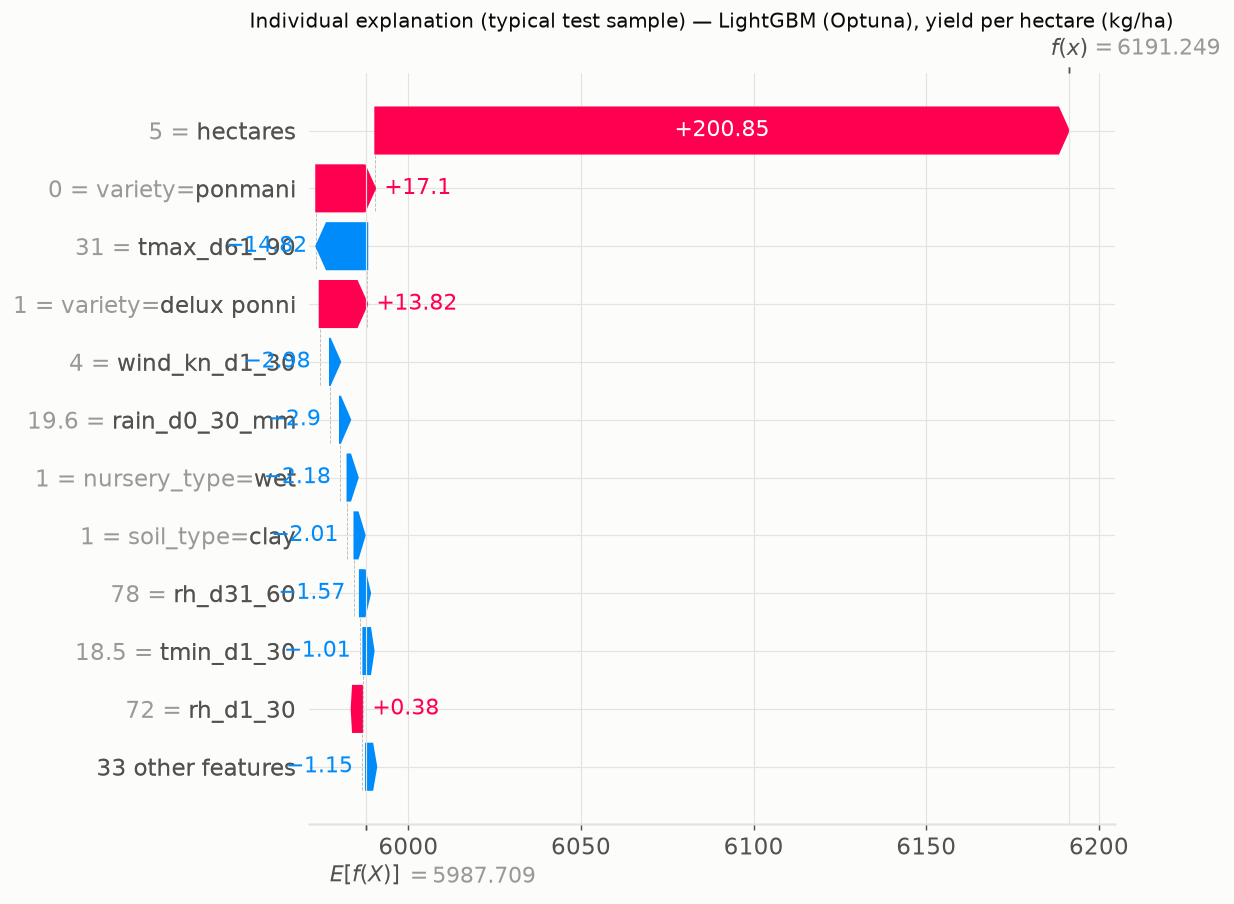

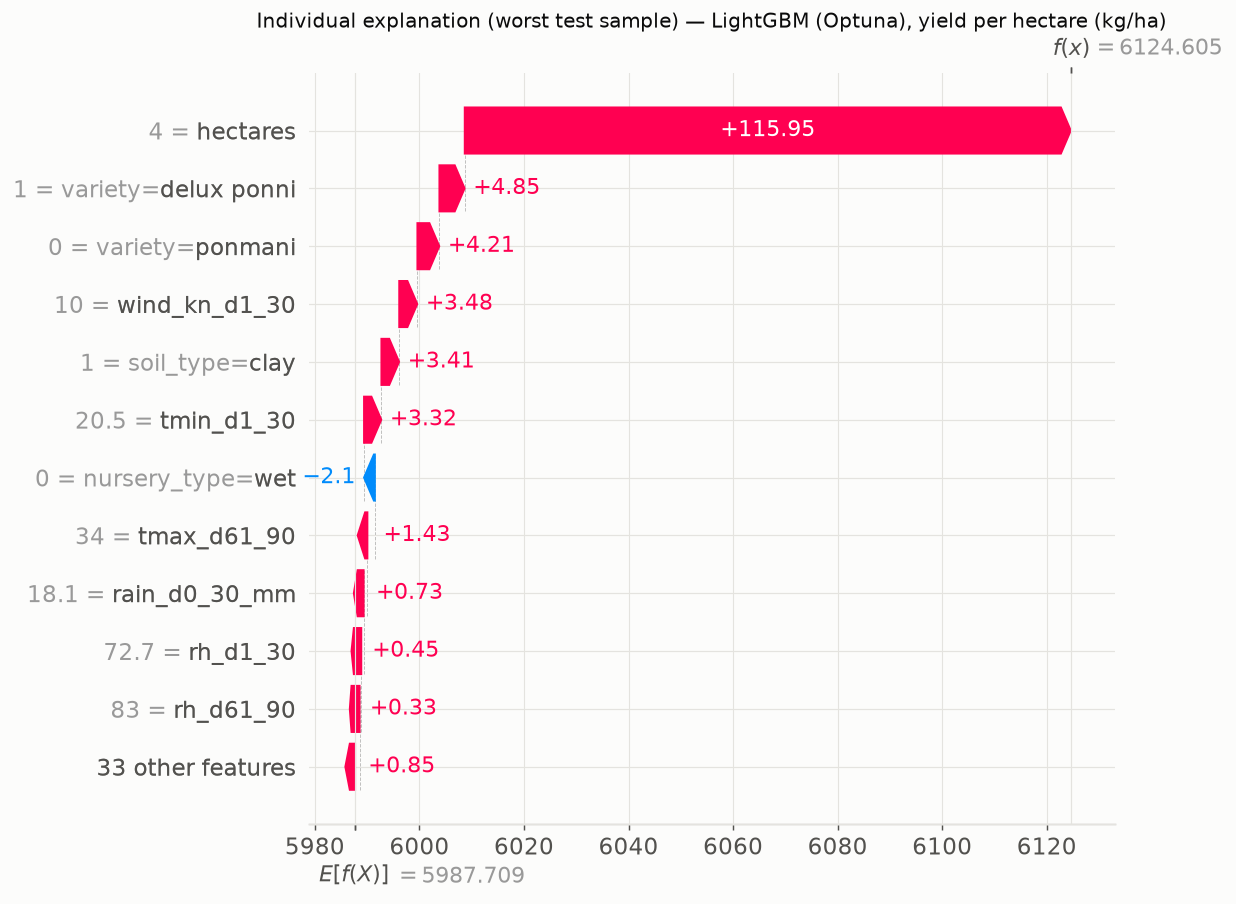

In [8]:
show('shap_per_ha_waterfall_typical.png', 650); show('shap_per_ha_waterfall_worst.png', 650)

## SHAP — total yield

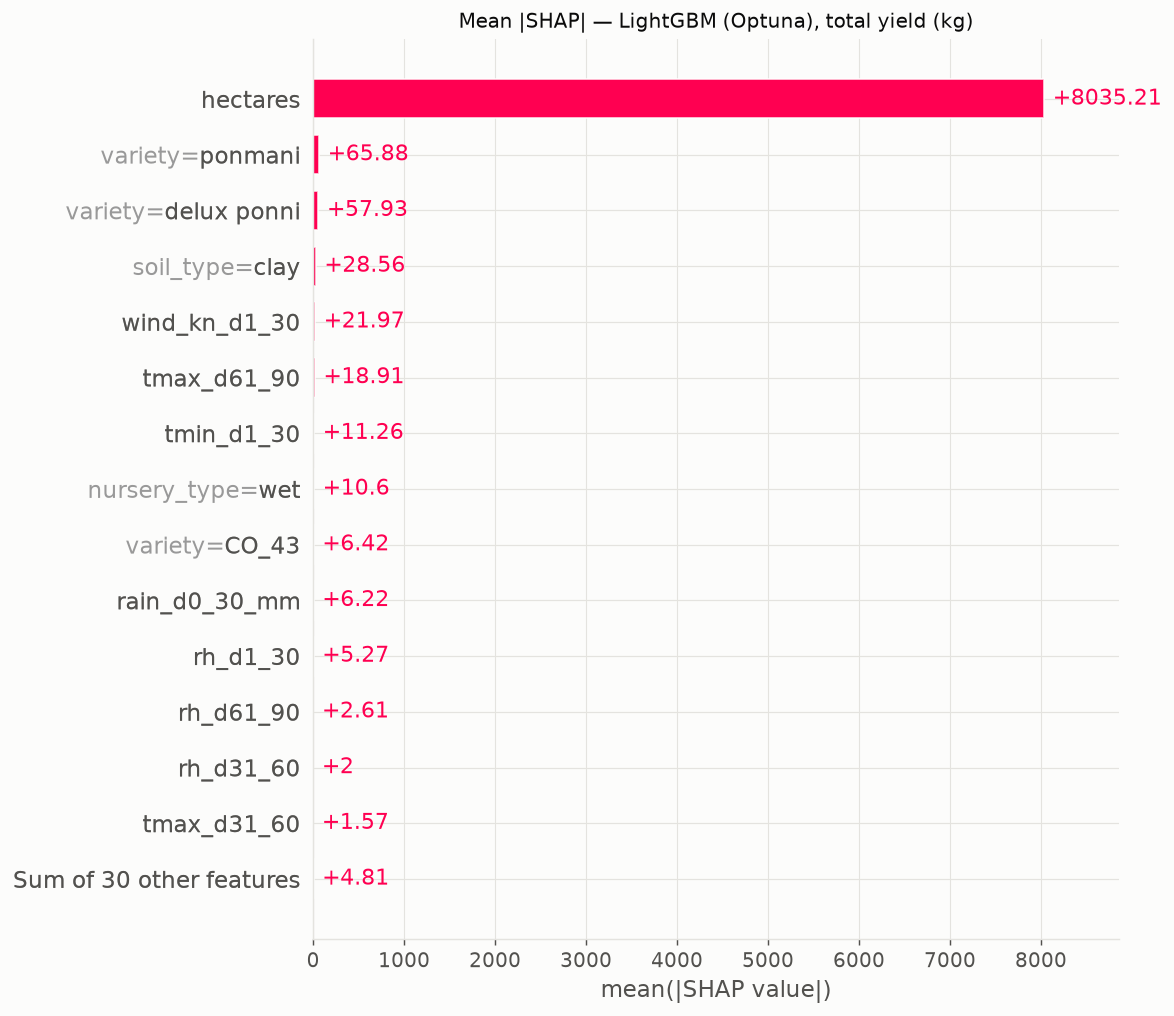

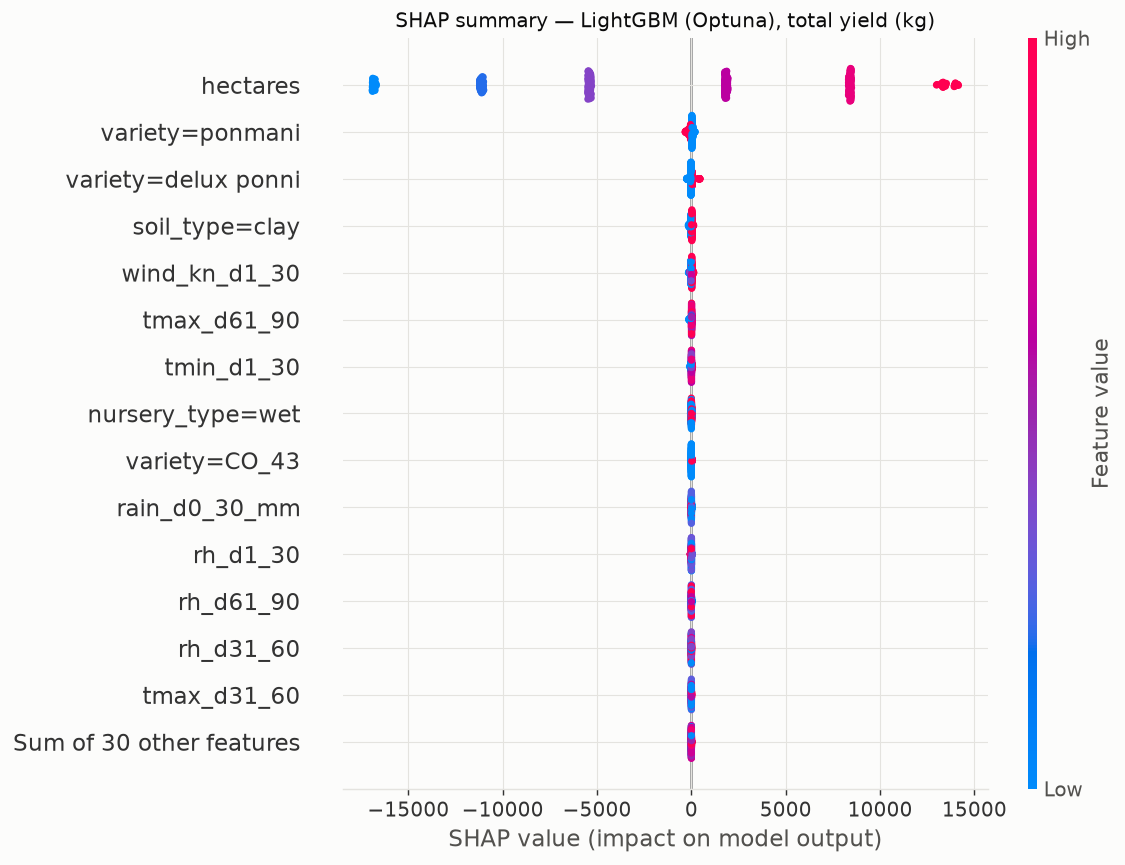

In [9]:
show('shap_total_bar.png', 650); show('shap_total_summary.png', 650)

In [10]:
pd.read_csv(M/'shap_importance_grouped_total.csv', index_col=0).head(10)

,mean_abs_shap,share_%
hectares,8035.213,97.053
variety,130.226,1.573
soil_type,28.563,0.345
wind_kn_d1_30,21.968,0.265
tmax_d61_90,18.907,0.228
tmin_d1_30,11.262,0.136
nursery_type,10.604,0.128
rain_d0_30_mm,6.224,0.075
rh_d1_30,5.269,0.064
rh_d61_90,2.613,0.032


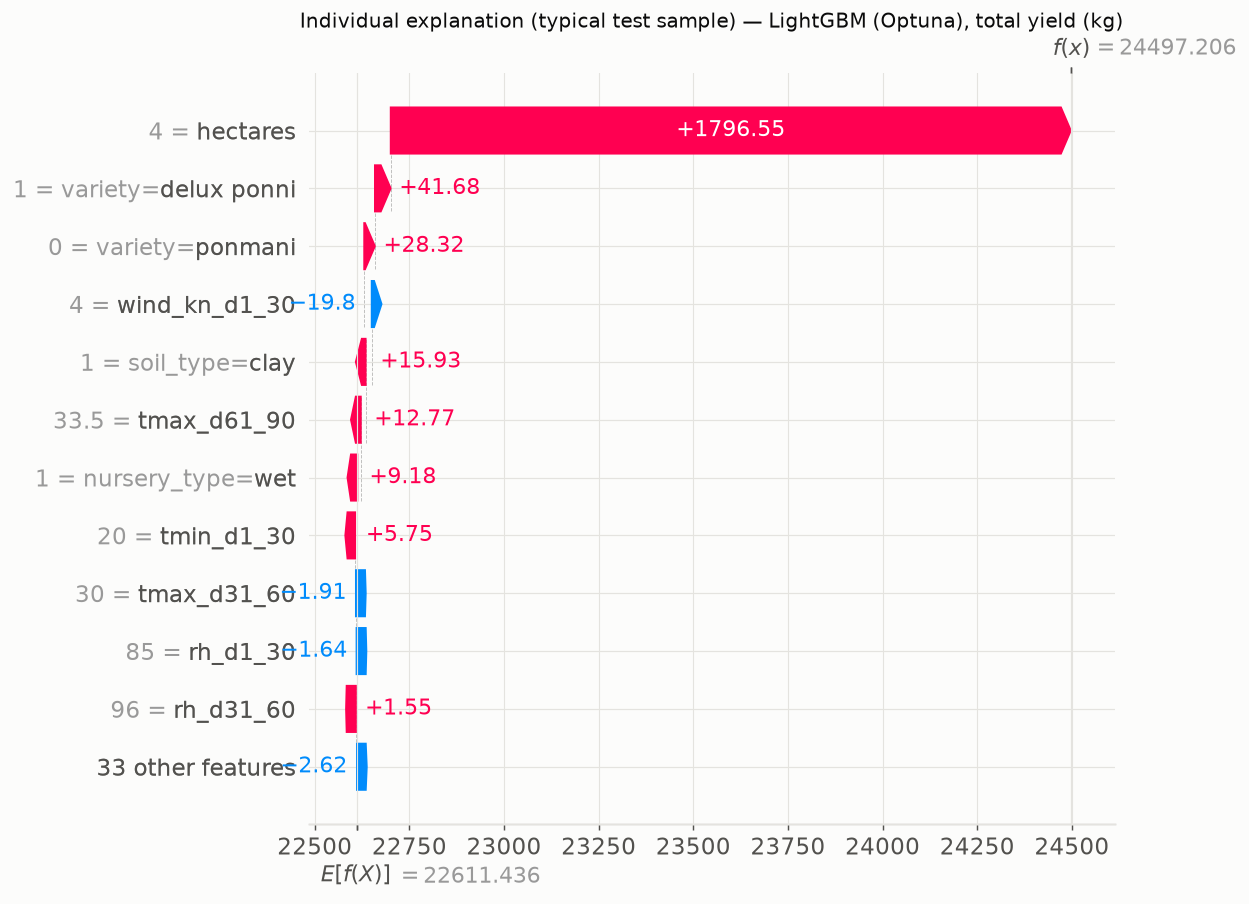

In [11]:
show('shap_total_waterfall_typical.png', 650)

## Error analysis (test set, per-hectare model)

In [12]:
print(json.dumps({k: v for k, v in final['per_ha']['error_analysis'].items()}, indent=1))

{
 "n": 468,
 "underpredicted_n": 244,
 "overpredicted_n": 224,
 "mean_underprediction": 144.5244294700919,
 "mean_overprediction": 183.00024573295792,
 "abs_error_p50": 133.78873004630668,
 "abs_error_p90": 320.67391479573416,
 "high_vs_low_error_profile": {
  "high_error_decile": {
   "hectares": 4.1,
   "actual": 5672.4
  },
  "low_error_decile": {
   "hectares": 4.0,
   "actual": 6020.4
  }
 }
}


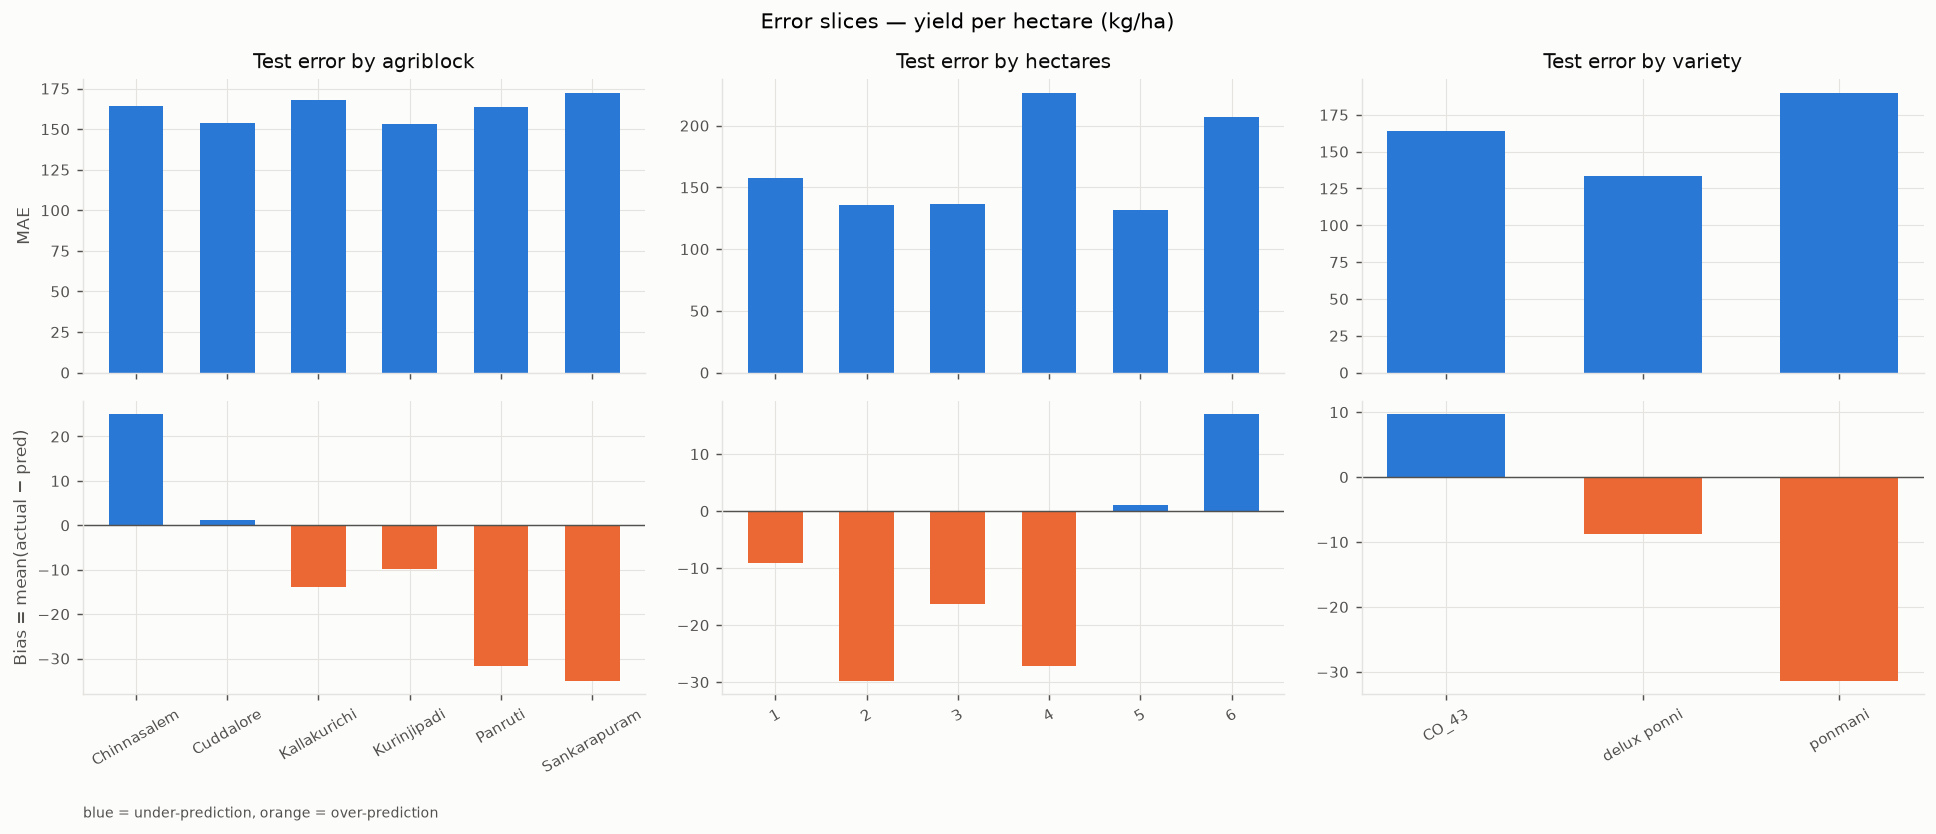

In [13]:
show('error_slices_per_ha.png', 1100)

In [14]:
for k in ('agriblock','hectares','variety','soil_type','nursery_type'):
    display(Markdown(f'**by {k}**')); display(pd.read_csv(M/f'error_by_{k}_per_ha.csv'))

**by agriblock**

,agriblock,n,MAE,bias,mean_actual
0,Chinnasalem,71,164.50,25.07,6011.24
1,Cuddalore,74,153.67,1.12,5980.42
2,Kallakurichi,71,168.06,-13.96,5960.03
3,Kurinjipadi,79,153.27,-9.83,5969.27
4,Panruti,73,163.53,-31.78,5957.78
5,Sankarapuram,100,172.27,-35.04,5970.55


**by hectares**

,hectares,n,MAE,bias,mean_actual
0,1,41,157.29,-9.14,5739.34
1,2,71,135.58,-29.79,5719.28
2,3,73,136.80,-16.24,5731.59
3,4,106,226.42,-27.13,6086.65
4,5,138,131.27,1.15,6196.83
5,6,39,207.14,17.03,6049.23


**by variety**

,variety,n,MAE,bias,mean_actual
0,CO_43,128,163.70,9.71,5994.73
1,delux ponni,164,133.53,-8.81,5988.38
2,ponmani,176,189.80,-31.39,5946.79


**by soil_type**

,soil_type,n,MAE,bias,mean_actual
0,alluvial,211,169.90,2.16,5982.15
1,clay,257,157.22,-24.06,5968.18


**by nursery_type**

,nursery_type,n,MAE,bias,mean_actual
0,dry,260,158.42,1.34,5983.62
1,wet,208,168.59,-29.21,5963.06


In [15]:
display(Markdown('**15 largest errors**')); display(pd.read_csv(M/'top_errors_per_ha.csv'))
display(Markdown('**15 smallest errors**')); display(pd.read_csv(M/'lowest_errors_per_ha.csv'))

**15 largest errors**

,hectares,agriblock,variety,soil_type,nursery_type,actual,predicted,residual,ape_%
0,4,Sankarapuram,delux ponni,clay,dry,5410.0,6124.6,-714.6,13.2
1,4,Kallakurichi,ponmani,clay,wet,5453.0,6129.9,-676.9,12.4
2,4,Panruti,ponmani,clay,wet,5463.0,6119.3,-656.3,12.0
3,5,Cuddalore,ponmani,clay,dry,5492.0,6124.2,-632.2,11.5
4,4,Cuddalore,delux ponni,alluvial,dry,5472.0,6092.7,-620.7,11.3
5,4,Kallakurichi,ponmani,clay,wet,5520.0,6129.9,-609.9,11.0
6,6,Chinnasalem,ponmani,alluvial,dry,6384.0,5784.1,599.9,9.4
7,4,Chinnasalem,delux ponni,clay,wet,5527.0,6121.8,-594.8,10.8
8,4,Kurinjipadi,delux ponni,alluvial,dry,5525.0,6117.9,-592.9,10.7
9,4,Chinnasalem,ponmani,clay,wet,5527.0,6114.3,-587.3,10.6


**15 smallest errors**

,hectares,agriblock,variety,soil_type,nursery_type,actual,predicted,residual,ape_%
0,6,Sankarapuram,ponmani,alluvial,dry,5941.0,5941.2,-0.2,0.0
1,5,Kallakurichi,delux ponni,clay,dry,6227.0,6228.0,-1.0,0.0
2,3,Kallakurichi,delux ponni,clay,dry,5757.0,5755.3,1.7,0.0
3,5,Kurinjipadi,CO_43,clay,dry,6213.0,6215.0,-2.0,0.0
4,5,Cuddalore,ponmani,clay,dry,6122.0,6124.2,-2.2,0.0
5,5,Sankarapuram,delux ponni,clay,wet,6227.0,6230.5,-3.5,0.1
6,5,Chinnasalem,delux ponni,alluvial,dry,6227.0,6222.8,4.2,0.1
7,5,Kallakurichi,ponmani,alluvial,wet,6161.0,6166.5,-5.5,0.1
8,2,Chinnasalem,delux ponni,clay,wet,5754.0,5747.6,6.4,0.1
9,4,Sankarapuram,CO_43,clay,wet,6122.0,6128.6,-6.6,0.1


## Findings

* **Hold-out test (468 rows, never used in tuning)** — best model by CV = LightGBM (Optuna):
  * Total yield: **R² 0.991, RMSE 881 kg, MAE 624 kg, MAPE 2.77%** (hectares-only OLS: R² 0.988, RMSE 1,010 kg).
  * Yield per hectare: **R² 0.496, RMSE 210 kg/ha, MAE 163 kg/ha, MAPE 2.77%** (mean predictor RMSE 296; hectares-only 238).
* **SHAP (per-ha)**: hectares 82.8% of mean |SHAP|, variety 9.2%, soil 1.7%, nursery 0.8%, and all location/weather columns combined 5.5%. Nitrogen/fertilizer columns have **zero** importance (they are constant per ha or identical to hectares). For total yield, hectares = 97%.
* Weather columns appearing in the SHAP ranking (`wind_kn_d1_30`, `tmax_d61_90`, …) should be read as **agriblock identifiers**, because weather is a deterministic function of block.
* **Error analysis**: errors are symmetric (244 under- vs 224 over-predictions). The largest errors are *low-yield farms of 4–6 ha* (actual ≈ 5,400–5,500 kg/ha, predicted ≈ 6,100) — the model predicts the group mean and cannot see what made those farms under-perform. 4-ha and 6-ha farms have the highest MAE (226 / 207 kg/ha) because yields in those groups are most dispersed; `ponmani` has the highest MAE and a slight over-prediction bias. Per-block MAE ranges only 153–172 kg/ha → no strong regional failure. No temporal analysis is possible (no time column).
